In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import numpy as np

_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src" / "constellation_denoiser").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from constellation_denoiser import *
%matplotlib inline

## Load and split

In [2]:
tx, rx = load_channel_data("Symbols_1m_1ch_PR_1.csv")
(tx_train, rx_train), (tx_val, rx_val), (tx_test, rx_test) = split(tx, rx)

## Error rate per constellation point (train)

In [3]:
tx_idx = get_indexes(tx_train)
rx_idx = get_indexes(rx_train)

errors = np.zeros(16)
totals = np.zeros(16)
for t, r in zip(tx_idx, rx_idx):
    totals[t] += 1
    if t != r:
        errors[t] += 1

error_rate = errors / totals

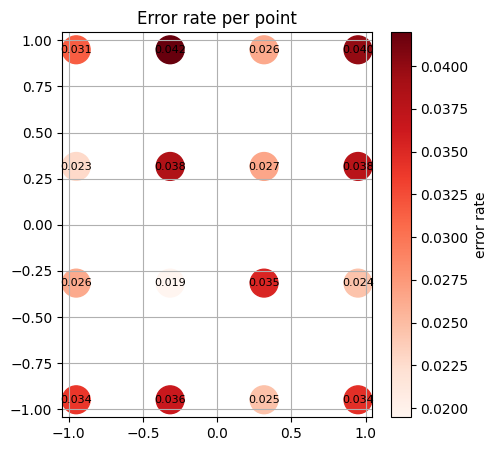

In [4]:
re, im = CONSTELLATION.real, CONSTELLATION.imag
plt.figure(figsize=(5, 5))
sc = plt.scatter(re, im, c=error_rate, cmap="Reds", s=400)
plt.colorbar(sc, label="error rate")
for i, (x, y) in enumerate(zip(re, im)):
    plt.annotate(f"{error_rate[i]:.3f}", (x, y), ha="center", va="center", fontsize=8)
plt.title("Error rate per point")
plt.grid(True)
plt.show()

## Error vs amplitude

In [5]:
amp = np.abs(CONSTELLATION)
corr_amp = np.corrcoef(amp, error_rate)[0, 1]
print(f"corr(error rate, amplitude) = {corr_amp:.4f}")

corr(error rate, amplitude) = 0.2359


## Linear ISI check

In [6]:
noise = rx_train - tx_train
corr_isi = np.corrcoef(np.abs(noise[1:]), np.abs(tx_train[:-1]))[0, 1]
print(f"corr(noise, neighbor amplitude) = {corr_isi:.4f}")

corr(noise, neighbor amplitude) = 0.0555


## Nonlinear ISI check

In [ ]:
from scipy.stats import spearmanr

rho, p = spearmanr(np.abs(noise[1:]), np.abs(tx_train[:-1]))
print(f"Spearman corr = {rho:.4f}, p-value = {p:.6f}")

Spearman corr = 0.0442, p-value = 0.000002


## Noise autocorrelation

In [8]:
for lag in [1, 2, 3, 5]:
    c = np.corrcoef(noise.real[:-lag], noise.real[lag:])[0, 1]
    print(f"lag={lag}: corr = {c:.4f}")

lag=1: corr = 0.0606
lag=2: corr = -0.0437
lag=3: corr = 0.0375
lag=5: corr = 0.0005
